# Tuần 07 — Khái quát dữ liệu (3/7)

**UET.MAT1052 — Xác suất thống kê**

**Hoàng Thị Điệp · Nghiêm Nguyễn Việt Dũng · Lê Thị Hường**

*Khoa Công nghệ Thông tin (VNU-UET-FIT)*

## Notebook minh họa

### Kỳ vọng, phương sai, phân phối liên tục và các định lý giới hạn

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, integrate

SEED = 2026

# 1. Kỳ vọng và phương sai

$$E(X)=\sum_x x\,p_X(x),\qquad \operatorname{Var}(X)=E(X^2)-[E(X)]^2.$$

In [2]:
def ky_vong_phuong_sai(xs, ps):
    xs, ps = np.asarray(xs, float), np.asarray(ps, float)
    mu = (xs * ps).sum()
    var = ((xs - mu) ** 2 * ps).sum()
    return mu, (xs ** 2 * ps).sum(), var, np.sqrt(var)

## 1.1. Ví dụ 1–3 — Hai sản phẩm, mỗi sản phẩm đạt chuẩn với xác suất 0.8

Chi phí $C=50+20X$ nghìn đồng (Ví dụ 2).

In [3]:
mu, ex2, var, sd = ky_vong_phuong_sai([0, 1, 2], [0.04, 0.32, 0.64])
print(f"E(X) = {mu:.2f}, E(X^2) = {ex2:.2f}, Var(X) = {var:.2f}, SD(X) = {sd:.3f}")
print(f"E(C) = 50 + 20 E(X) = {50 + 20 * mu:.0f} nghìn đồng")

E(X) = 1.60, E(X^2) = 2.88, Var(X) = 0.32, SD(X) = 0.566
E(C) = 50 + 20 E(X) = 82 nghìn đồng


## 1.2. Bài tập 1 — $E[g(N)]\ne g(E(N))$

$N\sim\operatorname{Binomial}(2,1/2)$, $X=1/(N+1)$.

In [4]:
n = np.arange(3)
p_n = stats.binom.pmf(n, 2, 0.5)
print("E(X)       =", round((1 / (n + 1) * p_n).sum(), 4), "(= 7/12)")
print("1/E(N + 1) =", round(1 / ((n + 1) * p_n).sum(), 4))

E(X)       = 0.5833 (= 7/12)
1/E(N + 1) = 0.5


## 1.3. Bài tập 2 — Đổi độ C sang độ F: $Y=1.8X+32$

In [5]:
print("E(Y)   =", 1.8 * 25 + 32)
print("Var(Y) =", round(1.8**2 * 3**2, 2))
print("SD(Y)  =", round(1.8 * 3, 2))

E(Y)   = 77.0
Var(Y) = 29.16
SD(Y)  = 5.4


## 1.4. Kỳ vọng và phương sai của các phân phối rời rạc đặc biệt

So sánh công thức với `mean()`, `var()` của SciPy (ví dụ: $p=0.3$, $n=10$, $N=50$, $K=20$, $\lambda=4$).

In [6]:
p, n, N, K, lam = 0.3, 10, 50, 20, 4
bang = {
    "Bernoulli": (stats.bernoulli(p), p, p * (1 - p)),
    "Nhị thức": (stats.binom(n, p), n * p, n * p * (1 - p)),
    "Siêu bội": (stats.hypergeom(M=N, n=K, N=n), n * K / N,
                 n * (K / N) * (1 - K / N) * (N - n) / (N - 1)),
    "Poisson": (stats.poisson(lam), lam, lam),
}
for ten, (X, e, v) in bang.items():
    print(f"{ten:10s} E: {X.mean():.4f} vs {e:.4f}   Var: {X.var():.4f} vs {v:.4f}")

Bernoulli  E: 0.3000 vs 0.3000   Var: 0.2100 vs 0.2100
Nhị thức   E: 3.0000 vs 3.0000   Var: 2.1000 vs 2.1000
Siêu bội   E: 4.0000 vs 4.0000   Var: 1.9592 vs 1.9592
Poisson    E: 4.0000 vs 4.0000   Var: 4.0000 vs 4.0000


# 2. Các biến ngẫu nhiên độc lập cùng phân phối

## 2.1. Ví dụ 5–6 — Hộp $\{0,0,1,1,1,2,3,3,4,4\}$

$$E(S_n)=n\mu,\quad SD(S_n)=\sigma\sqrt n,\qquad E(\overline X_n)=\mu,\quad SD(\overline X_n)=\sigma/\sqrt n.$$

In [7]:
hop = np.array([0, 0, 1, 1, 1, 2, 3, 3, 4, 4])
mu, sigma2 = hop.mean(), hop.var()
print(f"mu = {mu}, sigma^2 = {sigma2:.2f}, sigma = {np.sqrt(sigma2):.4f}")

for n in [25, 100]:
    print(f"n = {n:3d}: E(S) = {n*mu:6.1f}, SD(S) = {np.sqrt(n*sigma2):.3f}, "
          f"E(TB) = {mu}, SD(TB) = {np.sqrt(sigma2/n):.3f}")

mu = 1.9, sigma^2 = 2.09, sigma = 1.4457
n =  25: E(S) =   47.5, SD(S) = 7.228, E(TB) = 1.9, SD(TB) = 0.289
n = 100: E(S) =  190.0, SD(S) = 14.457, E(TB) = 1.9, SD(TB) = 0.145


Mô phỏng: mỗi hàng của `mau` là một mẫu gồm $n$ lần rút có hoàn lại; lặp 5000 lần.

In [8]:
bo_sinh = np.random.default_rng(SEED)
print("n   mean(tong)  mean(TB)  SD(tong)  SD(TB)")
for n in [25, 100]:
    mau = bo_sinh.choice(hop, size=(5000, n))
    tong = mau.sum(axis=1)
    trung_binh = mau.mean(axis=1)
    print(f"{n:<3d} {tong.mean():10.3f} {trung_binh.mean():9.3f} {tong.std():9.3f} {trung_binh.std():7.3f}")

n   mean(tong)  mean(TB)  SD(tong)  SD(TB)
25      47.409     1.896     7.147   0.286
100    189.898     1.899    14.495   0.145


Cỡ mẫu tăng gấp 4: độ lệch chuẩn của tổng tăng khoảng 2 lần, của trung bình giảm khoảng một nửa.

# 3. Bất đẳng thức Chebyshev và luật số lớn yếu

## 3.1. Bài tập 3 — Số lần đo đủ theo Chebyshev

$$P(|\overline X_n-\mu|\ge0.2)\le\frac{1}{n(0.2)^2}\le0.01.$$

In [9]:
sigma, eps, alpha = 1, 0.2, 0.01
n_can = int(np.ceil(sigma**2 / (alpha * eps**2)))
print("n >=", n_can)

n >= 2500


## 3.2. Minh họa luật số lớn yếu — đồng xu có $P(\text{ngửa})=0.7$

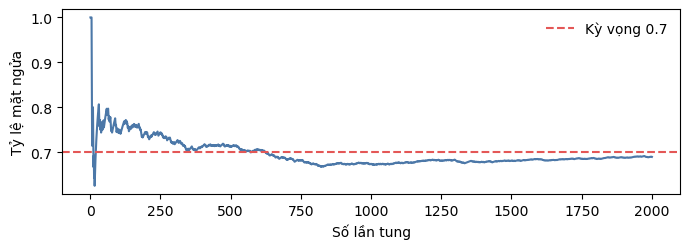

In [10]:
rng = np.random.default_rng(SEED)
x = rng.binomial(1, 0.7, size=2000)
n = np.arange(1, len(x) + 1)

plt.figure(figsize=(7, 2.6))
plt.plot(n, np.cumsum(x) / n, color="#4C78A8")
plt.axhline(0.7, color="#E45756", linestyle="--", label="Kỳ vọng 0.7")
plt.xlabel("Số lần tung")
plt.ylabel("Tỷ lệ mặt ngửa")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

Một lần mô phỏng, không phải chứng minh; tỷ lệ không tiến về 0.7 một cách đơn điệu.

# 4. Biến ngẫu nhiên liên tục

## 4.1. Bài tập 5, Ví dụ 7–8 — Kiểm tra mật độ, tính xác suất, kỳ vọng, phương sai bằng tích phân

In [11]:
print("Bài tập 5: tích phân của f = 2 trên (0, 0.5) =", integrate.quad(lambda t: 2, 0, 0.5)[0])

f = lambda t: 2 * t
print("VD7: P(0.2 < X < 0.6) =", round(integrate.quad(f, 0.2, 0.6)[0], 4))

ex = integrate.quad(lambda t: t * f(t), 0, 1)[0]
ex2 = integrate.quad(lambda t: t**2 * f(t), 0, 1)[0]
print(f"VD8: E(X) = {ex:.4f} (2/3), E(X^2) = {ex2:.4f}, Var(X) = {ex2 - ex**2:.4f} (1/18 = {1/18:.4f})")

Bài tập 5: tích phân của f = 2 trên (0, 0.5) = 1.0
VD7: P(0.2 < X < 0.6) = 0.32
VD8: E(X) = 0.6667 (2/3), E(X^2) = 0.5000, Var(X) = 0.0556 (1/18 = 0.0556)


# 5. Các phân phối liên tục đặc biệt

## 5.1. Phân phối đều — Ví dụ 9: $X\sim U(0,10)$

Trong SciPy, `uniform(loc=a, scale=b-a)`.

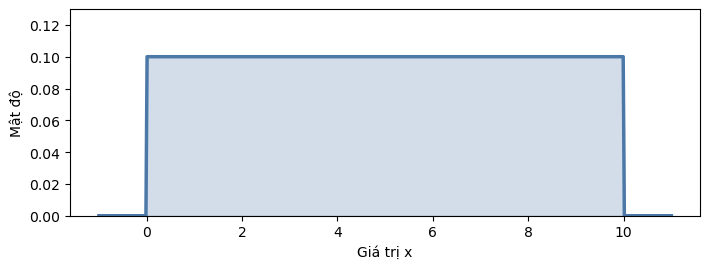

P(2 < X < 5) = 0.3
E(X) = 5.0  Var(X) = 8.3333


In [12]:
U = stats.uniform(loc=0, scale=10)
x = np.linspace(-1, 11, 500)
plt.figure(figsize=(7.2, 2.8))
plt.plot(x, U.pdf(x), color="#4C78A8", linewidth=2.5)
plt.fill_between(x, U.pdf(x), color="#4C78A8", alpha=0.25)
plt.xlabel("Giá trị x")
plt.ylabel("Mật độ")
plt.ylim(0, 0.13)
plt.tight_layout()
plt.show()

print("P(2 < X < 5) =", round(U.cdf(5) - U.cdf(2), 4))
print("E(X) =", U.mean(), " Var(X) =", round(U.var(), 4))

## 5.2. Phân phối chuẩn

`loc` là trung bình, `scale` là **độ lệch chuẩn** (không phải phương sai).

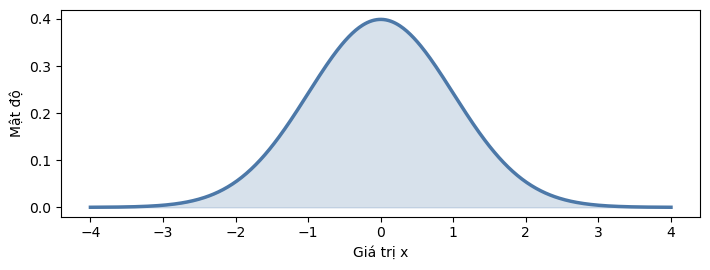

VD10: z = 2.0
Quy tắc thực nghiệm: P(|Z| < 1) = 0.6827
Quy tắc thực nghiệm: P(|Z| < 2) = 0.9545
Quy tắc thực nghiệm: P(|Z| < 3) = 0.9973


In [13]:
x = np.linspace(-4, 4, 500)
plt.figure(figsize=(7.2, 2.8))
plt.plot(x, stats.norm.pdf(x), color="#4C78A8", linewidth=2.5)
plt.fill_between(x, stats.norm.pdf(x), color="#4C78A8", alpha=0.22)
plt.xlabel("Giá trị x")
plt.ylabel("Mật độ")
plt.tight_layout()
plt.show()

print("VD10: z =", (86 - 70) / 8)
for k in [1, 2, 3]:
    print(f"Quy tắc thực nghiệm: P(|Z| < {k}) = {stats.norm.cdf(k) - stats.norm.cdf(-k):.4f}")

## 5.3. Ví dụ 11–12 — Dung tích chai $X\sim\mathcal N(500,2^2)$

In [14]:
from scipy.stats import norm

print("P(X <= 503)       =", round(norm.cdf(503, loc=500, scale=2), 4))
print("P(X > 503)        =", round(norm.sf(503, loc=500, scale=2), 4))
print("P(498 < X < 502)  =", round(norm.cdf(502, 500, 2) - norm.cdf(498, 500, 2), 4))
print("P(496 < X < 504)  =", round(norm.cdf(504, 500, 2) - norm.cdf(496, 500, 2), 4))
print("P(X > 504)        =", round(norm.sf(504, 500, 2), 4))
print("q_0.95            =", round(norm.ppf(0.95, loc=500, scale=2), 3), "ml")

P(X <= 503)       = 0.9332
P(X > 503)        = 0.0668
P(498 < X < 502)  = 0.6827
P(496 < X < 504)  = 0.9545
P(X > 504)        = 0.0228
q_0.95            = 503.29 ml


## 5.4. Phân phối mũ — Ví dụ 13

Trong SciPy, `expon(scale=1/λ)`; $E(X)=2$ phút nên $\lambda=0.5$.

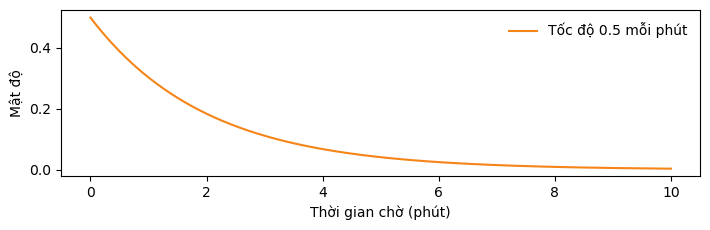

P(X > 3) = 0.2231


In [15]:
x = np.linspace(0, 10, 400)
plt.figure(figsize=(7.2, 2.4))
plt.plot(x, stats.expon.pdf(x, scale=2), color="#F58518", label="Tốc độ 0.5 mỗi phút")
plt.xlabel("Thời gian chờ (phút)")
plt.ylabel("Mật độ")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

print("P(X > 3) =", round(stats.expon.sf(3, scale=2), 4))

## 5.5. Phân phối $\chi^2$ và $t$ Student — nhận biết hình dạng

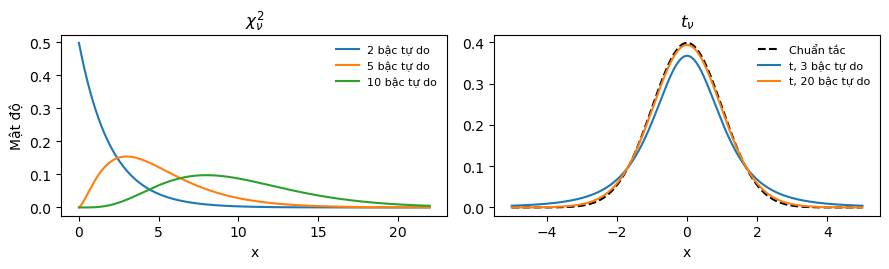

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8))
x = np.linspace(0.01, 22, 500)
for df in [2, 5, 10]:
    axes[0].plot(x, stats.chi2.pdf(x, df), label=f"{df} bậc tự do")
axes[0].set(title="$\\chi^2_\\nu$", xlabel="x", ylabel="Mật độ")

x = np.linspace(-5, 5, 500)
axes[1].plot(x, stats.norm.pdf(x), "k--", label="Chuẩn tắc")
for df in [3, 20]:
    axes[1].plot(x, stats.t.pdf(x, df), label=f"t, {df} bậc tự do")
axes[1].set(title="$t_\\nu$", xlabel="x")
for ax in axes:
    ax.legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

# 6. Định lý giới hạn trung tâm

$$S_n\approx\mathcal N(n\mu,n\sigma^2),\qquad\overline X_n\approx\mathcal N(\mu,\sigma^2/n).$$

## 6.1. Ví dụ 14 — Tổng và trung bình mẫu từ hộp thẻ

Cỡ mẫu $n$ = số lần rút để tính **một** tổng/trung bình; 5000 = số lần lặp để vẽ histogram.

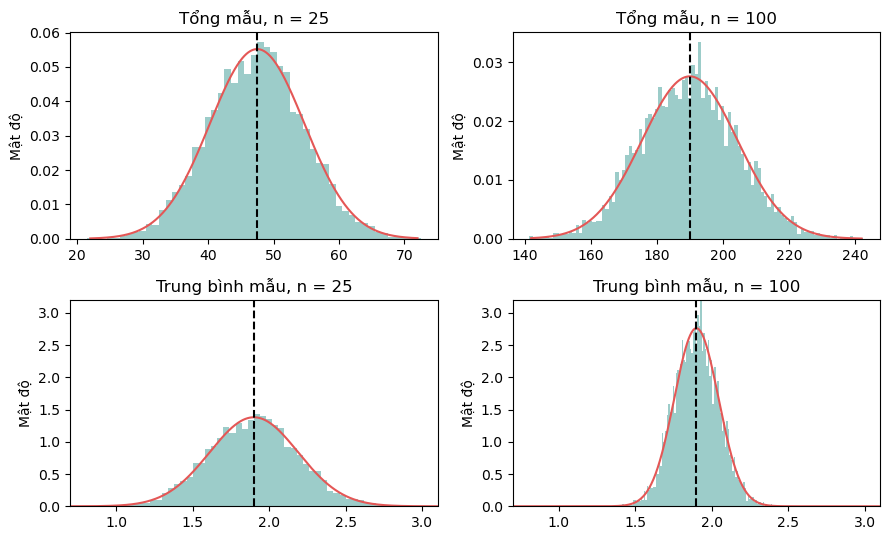

In [17]:
rng = np.random.default_rng(SEED)
box_samples = {n: rng.choice(hop, size=(5000, n), replace=True) for n in [25, 100]}

fig, axes = plt.subplots(2, 2, figsize=(9, 5.5))
for j, n in enumerate([25, 100]):
    sums = box_samples[n].sum(axis=1)
    bins = np.arange(sums.min() - 0.5, sums.max() + 1.5, 1)

    ax = axes[0, j]
    ax.hist(sums, bins=bins, density=True, color="#72B7B2", alpha=0.7)
    g = np.linspace(sums.min(), sums.max(), 500)
    ax.plot(g, stats.norm.pdf(g, n * mu, np.sqrt(n * sigma2)), color="#E45756")
    ax.axvline(n * mu, color="black", linestyle="--")
    ax.set(title=f"Tổng mẫu, n = {n}", ylabel="Mật độ")

    ax = axes[1, j]
    ax.hist(sums / n, bins=bins / n, density=True, color="#72B7B2", alpha=0.7)
    g = np.linspace(0.7, 3.1, 500)
    ax.plot(g, stats.norm.pdf(g, mu, np.sqrt(sigma2 / n)), color="#E45756")
    ax.axvline(mu, color="black", linestyle="--")
    ax.set(title=f"Trung bình mẫu, n = {n}", ylabel="Mật độ", xlim=(0.7, 3.1), ylim=(0, 3.2))
plt.tight_layout()
plt.show()

## 6.2. Từ phân phối mũ đến dạng gần chuẩn

$X$ có phân phối mũ, kỳ vọng và độ lệch chuẩn đều bằng 5 phút; vẽ $Z_n=(\overline X_n-5)/(5/\sqrt n)$.

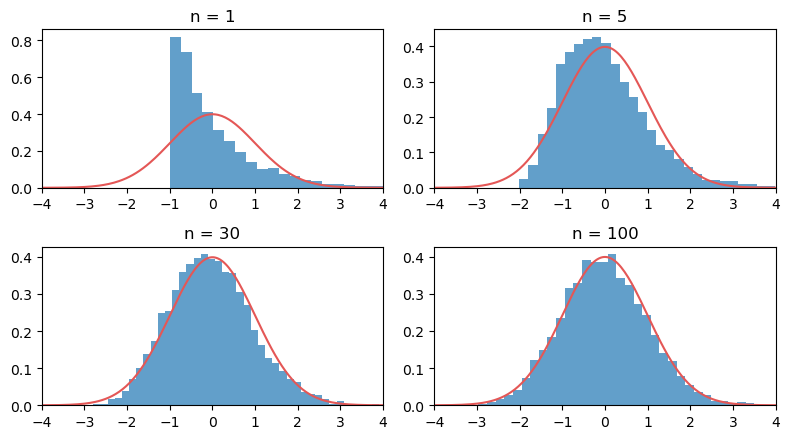

In [18]:
bo_sinh = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 2, figsize=(8, 4.5))
x = np.linspace(-4, 4, 200)
for ax, n in zip(axes.flat, [1, 5, 30, 100]):
    mau = bo_sinh.exponential(5, size=(5000, n))
    z = (mau.mean(axis=1) - 5) / (5 / np.sqrt(n))
    ax.hist(z, bins=40, density=True, alpha=0.7)
    ax.plot(x, stats.norm.pdf(x), color="#E45756")
    ax.set(title=f"n = {n}", xlim=(-4, 4))
plt.tight_layout()
plt.show()

## 6.3. Ví dụ 15 — $\overline X\approx\mathcal N(12, 6^2/64)$

In [19]:
sd_tb = 6 / np.sqrt(64)
print("SD(TB) =", sd_tb)
print("P(TB > 13.5) ≈", round(norm.sf(13.5, loc=12, scale=sd_tb), 4))

SD(TB) = 0.75
P(TB > 13.5) ≈ 0.0228


# 7. Bài tập vận dụng

## 7.1. Bài tập 6 — Dung lượng USB

In [20]:
mu6, ex2_6, var6, sd6 = ky_vong_phuong_sai([1, 2, 4, 8, 16], [0.05, 0.10, 0.35, 0.40, 0.10])
print(f"E(X) = {mu6:.2f} GB, E(X^2) = {ex2_6:.2f}")
print(f"Var(X) = {var6:.4f} GB^2 (rút gọn: {ex2_6 - mu6**2:.4f}), SD(X) = {sd6:.4f} GB")

E(X) = 6.45 GB, E(X^2) = 57.25
Var(X) = 15.6475 GB^2 (rút gọn: 15.6475), SD(X) = 3.9557 GB


## 7.2. Bài tập 8 — Thang máy: $S_{10}\sim\mathcal N(650, 250)$

In [21]:
print("P(S10 <= 700) =", round(norm.cdf(700, loc=650, scale=5 * np.sqrt(10)), 4))

P(S10 <= 700) = 0.9992


## 7.3. Bài tập 9 — Khoảng cách đến trường, $X\sim\operatorname{Exp}$ với kỳ vọng 5 km

In [22]:
E = stats.expon(scale=5)
print("1. P(X > 10)              =", round(E.sf(10), 4))
print("2. P(S100 <= 300)         ≈", round(norm.cdf(300, 500, 5 * 10), 6))
print("3. P(4.9 < TB100 < 5.2)   ≈", round(norm.cdf(5.2, 5, 0.5) - norm.cdf(4.9, 5, 0.5), 4))
print("4. P(4.9 < X < 5.2)       =", round(E.cdf(5.2) - E.cdf(4.9), 4))
print("5. P(4.9 < TB36 < 5.2)    ≈", round(norm.cdf(5.2, 5, 5/6) - norm.cdf(4.9, 5, 5/6), 4))

1. P(X > 10)              = 0.1353
2. P(S100 <= 300)         ≈ 3.2e-05
3. P(4.9 < TB100 < 5.2)   ≈ 0.2347
4. P(4.9 < X < 5.2)       = 0.0219
5. P(4.9 < TB36 < 5.2)    ≈ 0.1426


## 7.4. Bài tập 10 — Số linh kiện cần có

$$P(S_n\ge2000)\approx\Phi\!\left(\frac{100n-2000}{30\sqrt n}\right)\ge0.95.$$

In [23]:
for n in range(20, 26):
    p = norm.cdf((100 * n - 2000) / (30 * np.sqrt(n)))
    print(n, round(p, 4), "<- đạt" if p >= 0.95 else "")

20 0.5 
21 0.7665 
22 0.9224 
23 0.9815 <- đạt
24 0.9968 <- đạt
25 0.9996 <- đạt
